<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/07_Ransomware_Detection/QNN_Ransomware_Varalakshmi2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN for ransomware detection: Varalakshmi et al. 2024, step by step

**Paper.** I. Varalakshmi, A. K. Akila, R. Jazeera, S. Nanda Krishna, *"Ransomware Detection Using Quantum Neural Networks"*, 2024 International Conference on Smart Systems for Applications in Electrical Sciences, Computing and Networks (ICSCAN 2024), IEEE. DOI: [10.1109/ICSCAN62807.2024.10894015](https://doi.org/10.1109/ICSCAN62807.2024.10894015).

**What this notebook does.** It rebuilds the paper's pipeline end to end on a public copy of the dataset the paper describes:

1. downloads the ransomware / benign Windows PE-header table (62,485 files, 35,367 malicious and 27,118 non-malicious, exactly the paper's Table 1),
2. balances the classes by random undersampling and compresses the features with PCA (the two pre-processing steps the paper names),
3. maps the PCA components onto qubits, applies a **Quantum Fourier Transform (QFT)** feature-extraction block followed by a **variational quantum circuit** classifier trained with a cross-entropy loss and a classical optimiser (the architecture of the paper's Fig. 1),
4. trains classical baselines on exactly the same inputs,
5. compares everything with what the paper actually reports (a class-count table, an ROC curve and qualitative claims; the paper prints **no accuracy, precision, recall or F1 numbers**),
6. closes with a critical reading and exercises.

**How to run.** Open in Google Colab, choose a **CPU runtime**, and use *Runtime -> Run all*. With `FAST_MODE = True` (default in the configuration cell) everything finishes in a few minutes; set `FAST_MODE = False` for larger training sets and more seeds (about one hour on a laptop CPU). Nothing here needs a quantum computer: all circuits run on a noiseless state-vector simulator (PennyLane `default.qubit`).

**What you get at the end.** Test metrics (accuracy, precision, recall, F1, false-positive rate, AUC) of the QNN and four classical models on the same 4 inputs, confusion matrices, an ROC plot next to the paper's ROC curve, an ablation (with and without QFT, 4 versus 6 qubits, Adam versus plain gradient descent), a robustness check that removes duplicated files, and a side-by-side table with a verdict per claim of the paper.

## The paper in one page

* **Problem.** Detect ransomware (files that encrypt a victim's data for ransom) against benign software, with fewer false positives and less computation than classical detectors.
* **Decision.** Binary: *malicious* (ransomware) versus *non-malicious*.
* **Method.** A hybrid Quantum Neural Network (Fig. 1 of the paper): labelled malicious and non-malicious samples go through a *quantum feature extraction* stage (Quantum Fourier Transform plus a quantum feature map), then a *quantum classification* stage (a variational quantum circuit whose rotation angles are trained by a classical optimiser, "gradient descent or other traditional optimisation methods", with the cross-entropy loss), then a streaming real-time pipeline that raises an alert on a malicious decision. The paper writes the generic QNN ingredients (state preparation, rotation gates, CNOT, measurement, loss, update rule) but gives **no** circuit diagram, qubit count, ansatz, number of layers, optimiser, learning rate, epochs, batch size, train/test split, or random seed.
* **Data.** "Ransomware database", Table 1: 35,367 malicious samples and 27,118 non-malicious samples (62,485 files). The paper does not name or cite the dataset; the class counts match, to the file, the public *ransomware-detection-data-set* (PE-header features of Windows DLL/EXE files, with `Benign = 0` for malicious files), so this notebook uses it.
* **Pre-processing.** Random undersampling of the majority class "to equalize the class distribution" (abstract) and Principal Component Analysis "to reduce the number of classes [features] for quicker computation" (Section IV).
* **Environment.** Python 3, Jupyter, 12.1 / 15.9 GB RAM (a classical machine, so the QNN is simulated).
* **Claims that can be checked.** (1) Table 1 class counts. (2) Fig. 2: an ROC curve for the QNN. (3) The text says QNNs "outperform classical machine learning models" in accuracy, precision and recall, give "improved false-positive rates" and "reduced computational overhead", and detect ransomware in the early stage. **No numeric accuracy / precision / recall / F1 / AUC is printed anywhere in the paper**; the only quantitative evidence is Table 1 and the shape of the ROC curve.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | "Ransomware database", 35,367 malicious / 27,118 non-malicious (Table 1), source not named | Public GitHub copy of the PE-header ransomware dataset (62,485 rows, same class counts). Download from GitHub raw with a jsDelivr fallback, or upload your own `data_file.csv` |
| Features | Not stated ("file behaviour, encryption patterns, system interactions" in the text, but the table has none of these) | The 15 numeric PE-header columns of the dataset; `FileName` and `md5Hash` dropped. `# CHOICE:` signed `log1p` to tame heavy tails before scaling |
| Class balancing | Random undersampling | Random undersampling of the malicious class to 27,118 per class, then a stratified subsample for the simulator |
| Dimensionality reduction | PCA, number of components not stated | `# CHOICE:` `N_QUBITS = 4` components (one per qubit); also 6 in the ablation |
| Split | Not stated | `# CHOICE:` stratified 70 / 30 split of the balanced data, then a fixed-size training subset and a large test subset (sizes in the configuration cell). All transforms fitted on the training subset only |
| Feature map / QFT | "Quantum Fourier Transform" and a "quantum feature map" | `# CHOICE:` angle embedding (`RY(x_i)` on qubit *i*, features scaled to [0, pi]) followed by a full `QFT` on all qubits |
| Variational circuit | "VQC", parameters are rotation angles | `# CHOICE:` `StronglyEntanglingLayers`, 3 layers, 4 qubits = 36 trainable angles |
| Read-out | Measurement of an observable | `# CHOICE:` probability that qubit 0 is measured in `|1>` = P(ransomware); threshold 0.5 |
| Loss / optimiser | Cross-entropy; gradient descent "or other" | Binary cross-entropy; `# CHOICE:` Adam, learning rate 0.05, full batch (plain gradient descent in the ablation) |
| Epochs / seeds | Not stated | `# CHOICE:` 100 (fast) or 150 (full) epochs; 3 or 5 random seeds, mean +/- std |
| Simulator | Not stated | PennyLane `default.qubit`, exact state-vector, back-propagated gradients; no shot noise, no hardware |
| Classical baselines | "classical machine learning models", not named | `# CHOICE:` Random Forest, SVC (RBF), Logistic Regression, small MLP, on the same 4 inputs; Random Forest / SVC on all 15 features as a reference |
| Metrics | Accuracy, precision, recall in prose; ROC curve (Fig. 2); no numbers | Accuracy, precision, recall, F1, false-positive rate, AUC, wall-clock fit / predict time, confusion matrices |

In [1]:
# Install pinned versions tested for this notebook (Colab ships numpy, pandas, scikit-learn, matplotlib).
# The guard skips the install on machines where PennyLane is already importable.
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"])
    print("Installed pennylane==0.45.1. If Colab asks to restart the session, restart and run again.")
else:
    print("PennyLane already available, nothing to install.")

PennyLane already available, nothing to install.


In [2]:
# ---- Configuration: every tunable constant lives here ----
SEED = 42                 # master seed
FAST_MODE = False        # True: a few minutes class demo; False: larger training sets, more seeds
N_QUBITS = 4              # CHOICE: PCA components = qubits (paper does not state it)
N_LAYERS = 3              # CHOICE: depth of the variational block
USE_QFT = True            # the paper's QFT feature-extraction block
TEST_SIZE = 0.30          # CHOICE: share of the balanced data held out for testing
LR = 0.05                 # CHOICE: Adam learning rate
if FAST_MODE:
    N_TRAIN, N_TEST, EPOCHS = 300, 3000, 100
    SEEDS = [42, 43, 44]
    SWEEP_QUBITS, SWEEP_SEEDS = [4, 6], [42]
else:
    N_TRAIN, N_TEST, EPOCHS = 1000, 10000, 150
    SEEDS = [42, 43, 44, 45, 46]
    SWEEP_QUBITS, SWEEP_SEEDS = [4, 6], [42, 43]
DATA_DIR = "ransomware_data"       # cache folder for the downloaded CSV
DATA_PATH = None                   # or set to the path of an uploaded data_file.csv
IBM_TOKEN = ""                     # not used: this paper needs no quantum hardware, kept for convention
print(f"FAST_MODE={FAST_MODE}  N_TRAIN={N_TRAIN}  N_TEST={N_TEST}  EPOCHS={EPOCHS}  seeds={SEEDS}")

FAST_MODE=False  N_TRAIN=1000  N_TEST=10000  EPOCHS=150  seeds=[42, 43, 44, 45, 46]


In [3]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")
rng_master = np.random.default_rng(SEED)
np.random.seed(SEED)
print("pennylane", qml.__version__, "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1


## 1. Data: the ransomware PE-header table

Table 1 of the paper lists two classes, 35,367 malicious and 27,118 non-malicious samples. The public *ransomware-detection-data-set* (PE-header fields of Windows executables and DLLs; malicious files are VirusShare samples) contains 62,485 files with exactly these counts, so it is used here as the paper's database. In the file the column `Benign` is `0` for malicious files and `1` for benign files; we define `y = 1` for **ransomware / malicious** so that "attack" is the positive class, as in the rest of this repository.

The file is about 7.7 MB and is cached in `DATA_DIR`. If both download mirrors fail, upload `data_file.csv` and set `DATA_PATH`.

In [4]:
import requests
URLS = [
    "https://raw.githubusercontent.com/24vv1r1202-Chandra/ransomware-detection-data-set/main/data_file.csv",
    "https://cdn.jsdelivr.net/gh/24vv1r1202-Chandra/ransomware-detection-data-set@main/data_file.csv",  # same repo, CDN mirror
]
os.makedirs(DATA_DIR, exist_ok=True)
csv_path = DATA_PATH or os.path.join(DATA_DIR, "data_file.csv")
if not os.path.exists(csv_path):
    for u in URLS:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            open(csv_path, "wb").write(r.content); print("downloaded from", u); break
        except Exception as e:
            print("failed:", u, "->", e)
    else:
        raise RuntimeError("Could not download the data. Upload data_file.csv and set DATA_PATH.")
raw = pd.read_csv(csv_path)
raw.columns = raw.columns.str.strip()
print(raw.shape)
raw.head()

(62485, 18)


,FileName,md5Hash,Machine,DebugSize,DebugRVA,MajorImageVersion,MajorOSVersion,ExportRVA,ExportSize,IatVRA,MajorLinkerVersion,MinorLinkerVersion,NumberOfSections,SizeOfStackReserve,DllCharacteristics,ResourceSize,BitcoinAddresses,Benign
0,0124e21d-018c-4ce0-92a3-b9e205a76bc0.dll,79755c51e413ed3c6be4635fd729a6e1,332,0,0,0,4,0,0,8192,8,0,3,1048576,34112,672,0,1
1,05c8318f98a5d301d80000009c316005.vertdll.dll,95e19f3657d34a432eada93221b0ea16,34404,84,121728,10,10,126576,4930,0,14,10,8,262144,16864,1024,0,1
2,06054fba-5619-4a86-a861-ffb0464bef5d.dll,85c32641d77a54e19ba8ea4ab305c791,332,0,0,0,4,0,0,8192,8,0,3,1048576,34112,672,0,1
3,075822ac99a5d301660400009c316005.adhapi.dll,62e3b959d982ef534b66f819fe15f085,34404,84,19904,10,10,21312,252,18160,14,10,6,262144,16736,1040,0,1
4,090607dd9ba5d301ca0900009c316005.SensorsNative...,ae38c5f7d313ad0ff3bfb8826476767f,34404,84,97728,10,10,105792,1852,70592,14,10,7,262144,16736,1096,0,1


In [5]:
# Table 1 of the paper: class distribution
y_all = (raw["Benign"] == 0).astype(int).values            # 1 = malicious / ransomware (positive class)
table1 = pd.DataFrame({"Code": [1, 2], "Class": ["Malicious samples", "Non-malicious samples"],
                       "This notebook": [int((y_all == 1).sum()), int((y_all == 0).sum())],
                       "Paper (Table 1)": [35367, 27118]})
print(table1.to_string(index=False))

ID_COLS = ["FileName", "md5Hash", "Benign"]
FEATURES = [c for c in raw.columns if c not in ID_COLS]
X_all = raw[FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
assert X_all.notna().all().all(), "unexpected missing values"
const_cols = [c for c in FEATURES if X_all[c].nunique() == 1]
print("feature columns:", len(FEATURES), "| constant columns:", const_cols)
X_all = X_all.values.astype(float)

 Code                 Class  This notebook  Paper (Table 1)
    1     Malicious samples          35367            35367
    2 Non-malicious samples          27118            27118
feature columns: 15 | constant columns: []


### 1b. Two things the paper does not mention (checked once, used later)

* **Duplicates.** Many files share identical header fields. With a random split, a duplicate of a training file can land in the test set, which flatters every model. The main experiment follows the paper (no de-duplication) and a second experiment removes duplicated feature vectors (and the few that appear with both labels) before any splitting.
* **File type.** The class is strongly tied to the extension of the file name (`FileName` is *not* a model input, but it shows how the two classes were collected).

In [6]:
feat_df = pd.DataFrame(X_all, columns=FEATURES)
dup_mask = feat_df.assign(y=y_all).duplicated(keep="first").values                 # same features and same label
conflict_mask = feat_df.duplicated(keep=False).values & ~feat_df.assign(y=y_all).duplicated(keep=False).values
print(f"rows with a repeated (features, label) pair: {dup_mask.sum()} of {len(raw)}")
print(f"rows whose feature vector appears with both labels: {conflict_mask.sum()}")
# de-duplicated experiment: keep the first occurrence of each (features, label) pair, then drop any feature vector that is still repeated (it appears with both labels)
uniq = ~dup_mask
tmp = feat_df[uniq].duplicated(keep=False).values
keep_dedup = uniq.copy(); keep_dedup[np.where(uniq)[0][tmp]] = False
print("rows kept after de-duplication:", keep_dedup.sum(), "| malicious:", int(y_all[keep_dedup].sum()), "| non-malicious:", int((1 - y_all[keep_dedup]).sum()))

ext = raw["FileName"].astype(str).str.extract(r"\.([A-Za-z0-9]+)$")[0].str.lower().fillna("none")
print(pd.crosstab(ext.where(ext.isin(["dll", "exe"]), "other"), np.where(y_all == 1, "malicious", "non-malicious")))

rows with a repeated (features, label) pair: 30229 of 62485
rows whose feature vector appears with both labels: 7
rows kept after de-duplication: 32240 | malicious: 10675 | non-malicious: 21565


col_0  malicious  non-malicious
0                              
dll            0          23409
exe            0           3664
other      35367             45


## 2. Pre-processing: undersampling, split, scaling, PCA

For every random seed the pipeline is:

1. optional de-duplication (second experiment only);
2. **random undersampling** of the larger class so that both classes have the same size (the paper's balancing method);
3. a stratified split into a training pool and a test pool (`TEST_SIZE`);
4. a fixed-size, class-balanced **training subset** (`N_TRAIN`) and **test subset** (`N_TEST`), because a classical computer simulating the circuit cannot train on tens of thousands of samples quickly;
5. signed `log1p` (the PE fields span 0 to 4e9) -> `StandardScaler` -> `PCA(n_qubits)` -> `MinMaxScaler((0, pi))`, **all fitted on the training subset only**; test angles are clipped to [0, pi].

The same inputs (4 angles per file) feed the QNN and the classical baselines.

In [7]:
def balanced_indices(y, pool, rng):
    """Random undersampling: keep all of the minority class and a random subset of the majority class."""
    idx1, idx0 = pool[y[pool] == 1], pool[y[pool] == 0]
    n = min(len(idx1), len(idx0))
    return np.sort(np.concatenate([rng.choice(idx1, n, replace=False), rng.choice(idx0, n, replace=False)]))

def take_per_class(y, idx, n_total, rng):
    k = n_total // 2
    out = []
    for c in (0, 1):
        ic = idx[y[idx] == c]
        out.append(rng.choice(ic, min(k, len(ic)), replace=False))
    return np.sort(np.concatenate(out))

def signed_log1p(a):
    return np.sign(a) * np.log1p(np.abs(a))          # stateless transform, no fitting needed

def make_split(seed, dedup, n_qubits, n_train=None, n_test=None):
    n_train = N_TRAIN if n_train is None else n_train
    n_test = N_TEST if n_test is None else n_test
    rng = np.random.default_rng(seed)
    pool = np.where(keep_dedup)[0] if dedup else np.arange(len(y_all))
    bal = balanced_indices(y_all, pool, rng)                                              # random undersampling
    tr_pool, te_pool = train_test_split(bal, test_size=TEST_SIZE, stratify=y_all[bal], random_state=seed)
    tr = take_per_class(y_all, tr_pool, n_train, rng)
    te = take_per_class(y_all, te_pool, n_test, rng)
    A_tr, A_te = signed_log1p(X_all[tr]), signed_log1p(X_all[te])
    sc = StandardScaler().fit(A_tr)                                                       # fitted on training subset only
    S_tr, S_te = sc.transform(A_tr), sc.transform(A_te)
    pca = PCA(n_components=n_qubits, random_state=seed).fit(S_tr)
    P_tr, P_te = pca.transform(S_tr), pca.transform(S_te)
    mm = MinMaxScaler((0, np.pi)).fit(P_tr)
    Z_tr, Z_te = mm.transform(P_tr), np.clip(mm.transform(P_te), 0, np.pi)
    return dict(tr=tr, te=te, tr_pool=tr_pool, te_pool=te_pool, y_tr=y_all[tr], y_te=y_all[te],
                Z_tr=Z_tr, Z_te=Z_te, S_tr=S_tr, S_te=S_te, pca=pca, sc=sc, n_bal=len(bal))

sp = make_split(SEED, dedup=False, n_qubits=N_QUBITS)
print("balanced size per class:", sp["n_bal"] // 2, "| train:", sp["Z_tr"].shape, "| test:", sp["Z_te"].shape)
print("PCA explained variance ratio:", sp["pca"].explained_variance_ratio_.round(3), "sum =", sp["pca"].explained_variance_ratio_.sum().round(3))
print("train angle range:", sp["Z_tr"].min().round(2), sp["Z_tr"].max().round(2), "| test angle range after clipping:", sp["Z_te"].min().round(2), sp["Z_te"].max().round(2))

balanced size per class: 27118 | train: (1000, 4) | test: (10000, 4)
PCA explained variance ratio: [0.334 0.114 0.107 0.073] sum = 0.629
train angle range: 0.0 3.14 | test angle range after clipping: 0.0 3.14


## 3. The quantum circuit (paper's Fig. 1)

Fig. 1 has two quantum blocks. **Quantum feature extraction**: the classical vector is mapped onto qubits (feature map) and a **Quantum Fourier Transform** is applied. **Quantum classification**: a variational circuit with trainable rotation angles, a measurement, and a classical optimiser minimising the cross-entropy loss.

Concretely (all `# CHOICE:` details are listed in the table above):

```
|0>^n --RY(x_1..x_n)--> QFT --> StronglyEntanglingLayers(theta) --> measure qubit 0
```

`P(qubit 0 = 1)` is read as the probability that the file is ransomware and compared with a threshold of 0.5. The loss is the binary cross-entropy

L(theta) = - (1/N) sum_i [ y_i log p_i + (1 - y_i) log(1 - p_i) ].

PennyLane's exact simulator (`default.qubit`) back-propagates through the circuit, so every epoch uses the true gradient of the whole training set (no shot noise).

In [8]:
def make_qnode(n_qubits, n_layers, use_qft):
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="autograd", diff_method="backprop")
    def circuit(x, w):
        qml.AngleEmbedding(x, wires=range(n_qubits), rotation="Y")     # quantum feature map
        if use_qft:
            qml.QFT(wires=range(n_qubits))                              # quantum Fourier transform block
        qml.StronglyEntanglingLayers(w, wires=range(n_qubits))          # variational classifier
        return qml.probs(wires=0)
    return circuit

demo = make_qnode(N_QUBITS, N_LAYERS, USE_QFT)
w_demo = np.zeros(qml.StronglyEntanglingLayers.shape(N_LAYERS, N_QUBITS))
print(qml.draw(demo, level="top")(np.zeros(N_QUBITS), w_demo))
print("trainable angles:", w_demo.size)

0: ─╭AngleEmbedding(M0)─╭QFT─╭StronglyEntanglingLayers(M1)─┤  Probs
1: ─├AngleEmbedding(M0)─├QFT─├StronglyEntanglingLayers(M1)─┤       
2: ─├AngleEmbedding(M0)─├QFT─├StronglyEntanglingLayers(M1)─┤       
3: ─╰AngleEmbedding(M0)─╰QFT─╰StronglyEntanglingLayers(M1)─┤       

M0 = 
[0. 0. 0. 0.]
M1 = 
[[[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]

 [[0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]
  [0. 0. 0.]]]
trainable angles: 36


## 4. Training the QNN

`train_qnn` initialises the angles uniformly in [0, 2 pi) from the seed, then runs `EPOCHS` full-batch updates. The default optimiser is Adam (`# CHOICE:` the paper only says "gradient descent or other traditional optimisation methods"); `optimizer="gd"` applies the plain rule theta_new = theta_old - eta * grad L(theta) quoted in the paper.

  epoch    1/150  loss 0.6967


  epoch   31/150  loss 0.4105


  epoch   61/150  loss 0.3868


  epoch   91/150  loss 0.3828


  epoch  121/150  loss 0.3825


  epoch  150/150  loss 0.3823


fit 42.7s, predict 10000 files 1.74s | test accuracy 0.8469


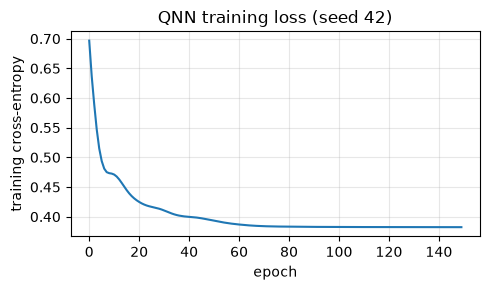

In [9]:
def bce(p1, y):
    p1 = np.clip(p1, 1e-9, 1 - 1e-9)
    return -np.mean(y * np.log(p1) + (1 - y) * np.log(1 - p1))

def qnn_predict_proba(circuit, w, Z, chunk=4000):
    out = [np.array(circuit(pnp.array(Z[i:i + chunk], requires_grad=False), w))[:, 1] for i in range(0, len(Z), chunk)]
    return np.concatenate(out)

def train_qnn(Z_tr, y_tr, seed, n_qubits=None, n_layers=None, use_qft=None, epochs=None, optimizer="adam", lr=None, verbose=True):
    n_qubits = N_QUBITS if n_qubits is None else n_qubits
    n_layers = N_LAYERS if n_layers is None else n_layers
    use_qft = USE_QFT if use_qft is None else use_qft
    epochs = EPOCHS if epochs is None else epochs
    lr = (LR if optimizer == "adam" else 0.5) if lr is None else lr
    circuit = make_qnode(n_qubits, n_layers, use_qft)
    shape = qml.StronglyEntanglingLayers.shape(n_layers, n_qubits)
    w = pnp.array(np.random.default_rng(seed).uniform(0, 2 * np.pi, shape), requires_grad=True)
    X = pnp.array(Z_tr, requires_grad=False); y = pnp.array(y_tr.astype(float), requires_grad=False)
    def loss_fn(w):
        p1 = circuit(X, w)[:, 1]
        p1 = pnp.clip(p1, 1e-9, 1 - 1e-9)
        return -pnp.mean(y * pnp.log(p1) + (1 - y) * pnp.log(1 - p1))
    opt = qml.AdamOptimizer(lr) if optimizer == "adam" else qml.GradientDescentOptimizer(lr)
    losses = []
    t0 = time.perf_counter()
    for e in range(epochs):
        w, l = opt.step_and_cost(loss_fn, w)
        losses.append(float(l))
        if verbose and (e % max(1, epochs // 5) == 0 or e == epochs - 1):
            print(f"  epoch {e + 1:4d}/{epochs}  loss {float(l):.4f}")
    fit_s = time.perf_counter() - t0
    return circuit, w, np.array(losses), fit_s

t0 = time.perf_counter()
circuit, w_hat, losses, fit_s = train_qnn(sp["Z_tr"], sp["y_tr"], SEED)
t1 = time.perf_counter(); p_te = qnn_predict_proba(circuit, w_hat, sp["Z_te"]); pred_s = time.perf_counter() - t1
print(f"fit {fit_s:.1f}s, predict {len(p_te)} files {pred_s:.2f}s | test accuracy {accuracy_score(sp['y_te'], p_te > .5):.4f}")
plt.figure(figsize=(5, 3)); plt.plot(losses); plt.xlabel("epoch"); plt.ylabel("training cross-entropy"); plt.title("QNN training loss (seed 42)"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. Classical baselines and the full experiment

Four classical models (Random Forest with 200 trees, SVC with RBF kernel and `C = 1`, Logistic Regression, an MLP with two hidden layers of 16 and 8 units) are trained on **exactly the same 4 angles and the same training subset** as the QNN. Two extra references use all 15 standardised log-features: a Random Forest and an RBF SVC on the same small training subset, and a Random Forest on the whole training pool (the classical ceiling). Hyper-parameters are fixed in advance, so nothing is tuned on the test set.

The loop runs every seed for two settings: **paper-style** (no de-duplication) and **de-duplicated**.

In [10]:
def metrics(y, p1=None, yhat=None):
    yhat = (p1 > 0.5).astype(int) if yhat is None else yhat
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return dict(accuracy=accuracy_score(y, yhat), precision=precision_score(y, yhat, zero_division=0),
                recall=recall_score(y, yhat), f1=f1_score(y, yhat), fpr=fp / (fp + tn),
                auc=roc_auc_score(y, p1) if p1 is not None else np.nan, tn=tn, fp=fp, fn=fn, tp=tp)

def classical_models(seed):
    return {
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1),
        "SVC (rbf)": SVC(kernel="rbf", C=1.0, probability=False, random_state=seed),
        "LogisticRegression": LogisticRegression(max_iter=2000, random_state=seed),
        "MLP (16-8)": MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=800, random_state=seed),
    }

def score_of(model, Z):
    return model.decision_function(Z) if hasattr(model, "decision_function") and not hasattr(model, "predict_proba") else model.predict_proba(Z)[:, 1]

def fit_eval(name, inputs, model, Ztr, ytr, Zte, yte):
    t0 = time.perf_counter(); model.fit(Ztr, ytr); fit_s = time.perf_counter() - t0
    t1 = time.perf_counter(); s = score_of(model, Zte); yhat = model.predict(Zte); pred_s = time.perf_counter() - t1
    m = metrics(yte, p1=s, yhat=yhat)       # AUC uses the raw score (decision function / probability)
    return dict(model=name, inputs=inputs, fit_s=fit_s, pred_s=pred_s, **m), s

rows, keep = [], {}
for dedup in (False, True):
    setting = "de-duplicated" if dedup else "paper-style"
    for seed in SEEDS:
        sp_ = make_split(seed, dedup, N_QUBITS)
        circ_, w_, loss_, fit_s = train_qnn(sp_["Z_tr"], sp_["y_tr"], seed, verbose=False)
        t1 = time.perf_counter(); p = qnn_predict_proba(circ_, w_, sp_["Z_te"]); pred_s = time.perf_counter() - t1
        m = metrics(sp_["y_te"], p1=p)
        rows.append(dict(setting=setting, seed=seed, model="QNN (QFT + VQC)", inputs=f"{N_QUBITS} PCA angles", fit_s=fit_s, pred_s=pred_s, **m))
        if seed == SEEDS[0]:
            keep[(setting, "QNN (QFT + VQC)")] = (sp_["y_te"], p, loss_)
        for name, mod in classical_models(seed).items():
            r, s = fit_eval(name, f"{N_QUBITS} PCA angles", mod, sp_["Z_tr"], sp_["y_tr"], sp_["Z_te"], sp_["y_te"])
            rows.append(dict(setting=setting, seed=seed, **r))
            if seed == SEEDS[0]:
                keep[(setting, name)] = (sp_["y_te"], s, None)
        for name, mod in {"RandomForest": classical_models(seed)["RandomForest"], "SVC (rbf)": classical_models(seed)["SVC (rbf)"]}.items():
            r, s = fit_eval(name, "15 features (same train subset)", mod, sp_["S_tr"], sp_["y_tr"], sp_["S_te"], sp_["y_te"])
            rows.append(dict(setting=setting, seed=seed, **r))
        # classical ceiling: whole training pool, all 15 features (scaler fitted on the pool)
        Apool = signed_log1p(X_all[sp_["tr_pool"]]); scp = StandardScaler().fit(Apool)
        r, s = fit_eval("RandomForest", f"15 features (whole train pool, n={len(sp_['tr_pool'])})", classical_models(seed)["RandomForest"],
                        scp.transform(Apool), y_all[sp_["tr_pool"]], scp.transform(signed_log1p(X_all[sp_["te"]])), sp_["y_te"])
        rows.append(dict(setting=setting, seed=seed, **r))
        print(f"[{setting}] seed {seed}: QNN acc {m['accuracy']:.4f} auc {m['auc']:.4f} (fit {fit_s:.0f}s)")
res = pd.DataFrame(rows)
print("done:", len(res), "result rows")

[paper-style] seed 42: QNN acc 0.8469 auc 0.9511 (fit 59s)


[paper-style] seed 43: QNN acc 0.8589 auc 0.9569 (fit 38s)


[paper-style] seed 44: QNN acc 0.8544 auc 0.9366 (fit 79s)


[paper-style] seed 45: QNN acc 0.8598 auc 0.9546 (fit 74s)


[paper-style] seed 46: QNN acc 0.8573 auc 0.9513 (fit 62s)


[de-duplicated] seed 42: QNN acc 0.9185 auc 0.9720 (fit 52s)


[de-duplicated] seed 43: QNN acc 0.8993 auc 0.9641 (fit 54s)


[de-duplicated] seed 44: QNN acc 0.9221 auc 0.9674 (fit 55s)


[de-duplicated] seed 45: QNN acc 0.9163 auc 0.9718 (fit 64s)


[de-duplicated] seed 46: QNN acc 0.9054 auc 0.9671 (fit 64s)
done: 80 result rows


In [11]:
cols = ["accuracy", "precision", "recall", "f1", "fpr", "auc", "fit_s", "pred_s"]
summary = res.groupby(["setting", "inputs", "model"])[cols].agg(["mean", "std"]).round(4)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
for setting in ["paper-style", "de-duplicated"]:
    print(f"\n===== {setting}  (mean +/- std over {len(SEEDS)} seeds, test subset of {N_TEST} files) =====")
    d = res[res.setting == setting].groupby(["inputs", "model"])[cols].agg(["mean", "std"])
    out = pd.DataFrame({c: d[c]["mean"].map("{:.4f}".format) + " +/- " + d[c]["std"].fillna(0).map("{:.4f}".format) for c in cols})
    print(out.to_string())


===== paper-style  (mean +/- std over 5 seeds, test subset of 10000 files) =====
                                                                     accuracy          precision             recall                 f1                fpr                auc                fit_s             pred_s
inputs                                  model                                                                                                                                                                       
15 features (same train subset)         RandomForest        0.9884 +/- 0.0013  0.9828 +/- 0.0032  0.9941 +/- 0.0024  0.9884 +/- 0.0013  0.0174 +/- 0.0033  0.9980 +/- 0.0011    1.5260 +/- 0.3114  0.5681 +/- 0.1516
                                        SVC (rbf)           0.9722 +/- 0.0015  0.9739 +/- 0.0017  0.9705 +/- 0.0043  0.9722 +/- 0.0016  0.0260 +/- 0.0019  0.9907 +/- 0.0014    0.0520 +/- 0.0110  1.4635 +/- 0.3266
15 features (whole train pool, n=37965) RandomForest        0.9964

                                                                     accuracy          precision             recall                 f1                fpr                auc               fit_s             pred_s
inputs                                  model                                                                                                                                                                      
15 features (same train subset)         RandomForest        0.9835 +/- 0.0031  0.9803 +/- 0.0024  0.9868 +/- 0.0044  0.9836 +/- 0.0032  0.0198 +/- 0.0024  0.9973 +/- 0.0004   1.6984 +/- 0.2773  0.4632 +/- 0.0548
                                        SVC (rbf)           0.9685 +/- 0.0023  0.9601 +/- 0.0058  0.9776 +/- 0.0020  0.9688 +/- 0.0022  0.0407 +/- 0.0062  0.9929 +/- 0.0009   0.0478 +/- 0.0175  1.0250 +/- 0.2067
15 features (whole train pool, n=14945) RandomForest        0.9939 +/- 0.0009  0.9921 +/- 0.0014  0.9958 +/- 0.0013  0.9939 +/- 0.0009  0.0079 +/- 0.001

## 6. Confusion matrices and ROC curves (re-drawing the paper's Fig. 2)

Confusion matrices use *malicious* as the positive class. The ROC panel overlays the QNN of this notebook, the classical models on the same inputs and the curve printed in the paper's Fig. 2. Reading the figure, the paper's curve passes through (FPR, TPR) = (0.01, 0.10), (0.2, 0.45), (0.4, 0.63), (0.6, 0.775), (0.8, 0.895), which is the analytic curve **TPR = sqrt(FPR)** (a smooth, exactly square-root curve with an area under the curve of 2/3 = 0.667). Real classifier ROC curves are step functions and are not this regular, so the figure looks like an illustration rather than the output of the trained model; we nevertheless use its AUC of about 0.667 as the paper's only quantitative detection result.

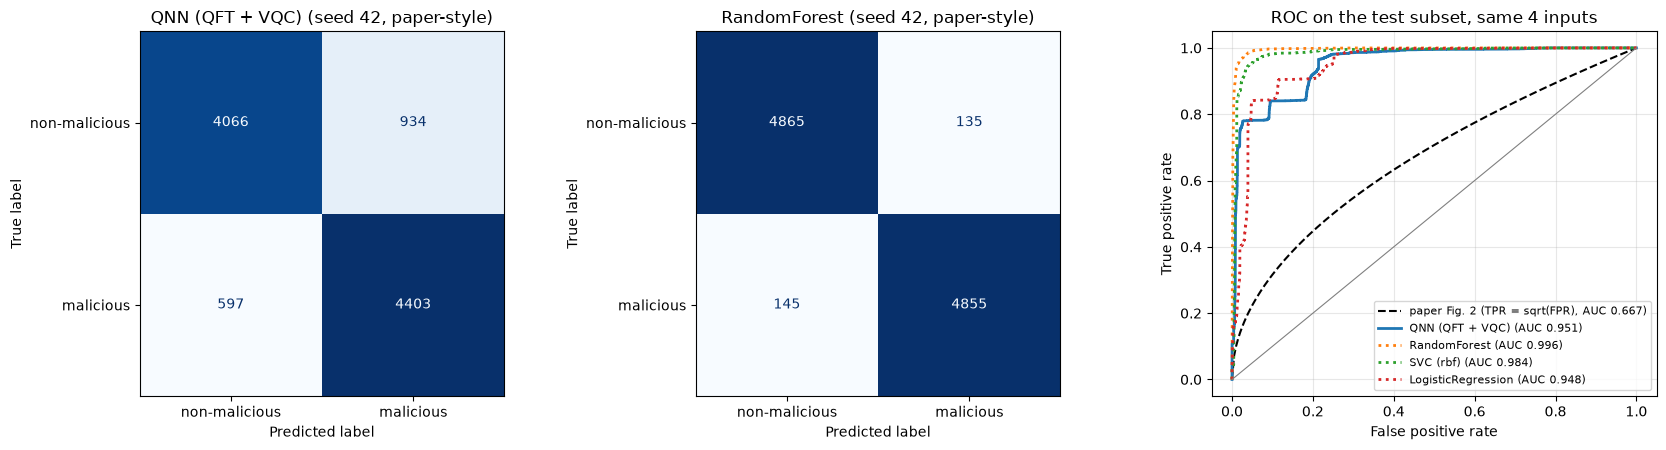

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, key in zip(axes[:2], [("paper-style", "QNN (QFT + VQC)"), ("paper-style", "RandomForest")]):
    y_, s_, _ = keep[key]
    yhat = (s_ > 0.5).astype(int)      # QNN and Random Forest scores are probabilities
    ConfusionMatrixDisplay(confusion_matrix(y_, yhat, labels=[0, 1]), display_labels=["non-malicious", "malicious"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{key[1]} (seed {SEEDS[0]}, paper-style)")
ax = axes[2]
fpr_grid = np.linspace(0, 1, 201)
ax.plot(fpr_grid, np.sqrt(fpr_grid), "k--", label="paper Fig. 2 (TPR = sqrt(FPR), AUC 0.667)")
for name, style in [("QNN (QFT + VQC)", "-"), ("RandomForest", ":"), ("SVC (rbf)", ":"), ("LogisticRegression", ":")]:
    y_, s_, _ = keep[("paper-style", name)]
    f_, t_, _ = roc_curve(y_, s_); ax.plot(f_, t_, style, lw=2, label=f"{name} (AUC {roc_auc_score(y_, s_):.3f})")
ax.plot([0, 1], [0, 1], color="grey", lw=.8); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC on the test subset, same 4 inputs"); ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

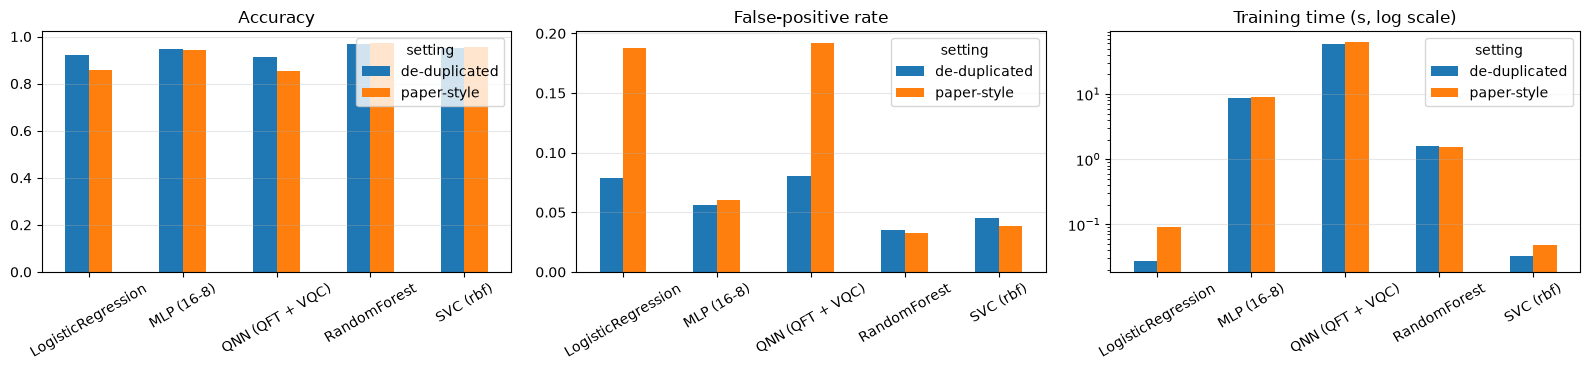

In [13]:
# Bar chart of mean accuracy / FPR / fit time over seeds, both settings (4 PCA-angle inputs only)
sub = res[res.inputs == f"{N_QUBITS} PCA angles"]
g = sub.groupby(["setting", "model"])[["accuracy", "fpr", "fit_s"]].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, title in zip(axes, ["accuracy", "fpr", "fit_s"], ["Accuracy", "False-positive rate", "Training time (s, log scale)"]):
    p = g.pivot(index="model", columns="setting", values=col)
    p.plot.bar(ax=ax, rot=30); ax.set_title(title); ax.set_xlabel(""); ax.grid(alpha=.3, axis="y")
    if col == "fit_s": ax.set_yscale("log")
plt.tight_layout(); plt.show()

## 7. Ablation: QFT, qubit count and optimiser

The paper's one design element is the QFT block. These cells test whether it matters (QFT on / off), whether more qubits (more PCA components) help, and what the paper's literal "gradient descent" update gives compared with Adam. Each configuration is trained for `EPOCHS` epochs on the paper-style split and scored on the test subset, with a Random Forest on the same inputs as the yardstick.

In [14]:
abl_rows = []
for nq in SWEEP_QUBITS:
    for qft in (True, False):
        for seed in SWEEP_SEEDS:
            sp_ = make_split(seed, False, nq)
            c_, w_, l_, fit_s = train_qnn(sp_["Z_tr"], sp_["y_tr"], seed, n_qubits=nq, use_qft=qft, verbose=False)
            p = qnn_predict_proba(c_, w_, sp_["Z_te"]); m = metrics(sp_["y_te"], p1=p)
            rf = RandomForestClassifier(200, random_state=seed, n_jobs=-1).fit(sp_["Z_tr"], sp_["y_tr"])
            abl_rows.append(dict(config=f"{nq} qubits, QFT={'on' if qft else 'off'}, Adam", seed=seed, qnn_acc=m["accuracy"], qnn_auc=m["auc"],
                                 qnn_fpr=m["fpr"], rf_acc_same_inputs=rf.score(sp_["Z_te"], sp_["y_te"]), fit_s=fit_s))
for seed in SWEEP_SEEDS:                           # plain gradient descent, the paper's literal update rule
    sp_ = make_split(seed, False, N_QUBITS)
    c_, w_, l_, fit_s = train_qnn(sp_["Z_tr"], sp_["y_tr"], seed, optimizer="gd", verbose=False)
    p = qnn_predict_proba(c_, w_, sp_["Z_te"]); m = metrics(sp_["y_te"], p1=p)
    abl_rows.append(dict(config=f"{N_QUBITS} qubits, QFT=on, plain gradient descent (lr 0.5)", seed=seed, qnn_acc=m["accuracy"], qnn_auc=m["auc"],
                         qnn_fpr=m["fpr"], rf_acc_same_inputs=np.nan, fit_s=fit_s))
abl = pd.DataFrame(abl_rows)
print(abl.groupby("config")[["qnn_acc", "qnn_auc", "qnn_fpr", "rf_acc_same_inputs", "fit_s"]].agg(["mean", "std"]).round(4).to_string())

                                                  qnn_acc         qnn_auc         qnn_fpr         rf_acc_same_inputs             fit_s         
                                                     mean     std    mean     std    mean     std               mean     std      mean      std
config                                                                                                                                         
4 qubits, QFT=off, Adam                            0.8568  0.0004  0.9568  0.0026  0.1985  0.0004             0.9738  0.0026   45.1682   0.4802
4 qubits, QFT=on, Adam                             0.8529  0.0085  0.9540  0.0041  0.1895  0.0038             0.9738  0.0026   44.1947   0.9518
4 qubits, QFT=on, plain gradient descent (lr 0.5)  0.8510  0.0105  0.9498  0.0036  0.1884  0.0003                NaN     NaN   72.4834  17.8442
6 qubits, QFT=off, Adam                            0.8354  0.0071  0.9359  0.0006  0.2117  0.0016             0.9780  0.0029  183.8373  

## 8. Side by side with the paper

The paper prints no accuracy, precision, recall, F1 or AUC value, so most claims are qualitative. The rule used for verdicts:

* numeric claim: **reproduced** if within 2 accuracy points or 0.02 of the paper's value (here 0.02 on AUC), otherwise **not reached** / **exceeded** with the gap;
* "QNN outperforms classical models": **reproduced** only if the mean QNN metric is at least as good as every classical baseline on the same inputs **not reached** otherwise (the gap to the best classical baseline is printed);
* claims that need hardware, real-time streams or data this table does not contain: **cannot be checked**.

In [15]:
S = res[res.setting == "paper-style"]
same = S[S.inputs == f"{N_QUBITS} PCA angles"]
q = same[same.model.str.startswith("QNN")][["accuracy", "precision", "recall", "f1", "fpr", "auc", "fit_s", "pred_s"]].mean()
qs = same[same.model.str.startswith("QNN")][["accuracy", "precision", "recall", "f1", "fpr", "auc"]].std()
cl = same[~same.model.str.startswith("QNN")].groupby("model")[["accuracy", "precision", "recall", "f1", "fpr", "auc", "fit_s", "pred_s"]].mean()

def beats_all(metric, higher_better=True):
    base = cl[metric]
    if higher_better:
        n_beaten = int((q[metric] > base).sum()); ok = bool((q[metric] >= base.max()))
        gap = q[metric] - base.max()
    else:
        n_beaten = int((q[metric] < base).sum()); ok = bool((q[metric] <= base.min()))
        gap = base.min() - q[metric]
    return ok, n_beaten, gap

auc_paper = 2 / 3                                   # digitised from Fig. 2: TPR = sqrt(FPR)
claims = []
claims.append(("Table 1: 35,367 malicious samples", "35,367", f"{int((y_all == 1).sum()):,}", "reproduced" if (y_all == 1).sum() == 35367 else "not reached"))
claims.append(("Table 1: 27,118 non-malicious samples", "27,118", f"{int((y_all == 0).sum()):,}", "reproduced" if (y_all == 0).sum() == 27118 else "not reached"))
d_auc = q["auc"] - auc_paper
claims.append(("Fig. 2: QNN ROC AUC (digitised, about 0.667)", "0.667", f"{q['auc']:.3f} +/- {qs['auc']:.3f}",
               "reproduced" if abs(d_auc) <= 0.02 else (f"exceeded by {d_auc:+.3f}" if d_auc > 0 else f"not reached ({d_auc:+.3f})")))
for metric, label, hb in [("accuracy", "accuracy", True), ("precision", "precision", True), ("recall", "recall", True)]:
    ok, nb, gap = beats_all(metric, hb)
    claims.append((f"Text: QNN beats classical models in {label}", "higher than classical (no number)", f"QNN {q[metric]:.4f} vs best classical {cl[metric].max():.4f} ({cl[metric].idxmax()}); beats {nb}/{len(cl)}",
                   "reproduced" if ok else f"not reached (gap {gap:+.4f})"))
ok, nb, gap = beats_all("fpr", False)
claims.append(("Text: improved false-positive rate", "lower than classical (no number)", f"QNN {q['fpr']:.4f} vs lowest classical {cl['fpr'].min():.4f} ({cl['fpr'].idxmin()}); better than {nb}/{len(cl)}",
               "reproduced" if ok else f"not reached (gap {gap:+.4f})"))
claims.append(("Text: reduced computational overhead", "less than classical (no number)", f"QNN fit {q['fit_s']:.1f}s, predict {q['pred_s']:.2f}s vs RF fit {cl.loc['RandomForest','fit_s']:.2f}s, predict {cl.loc['RandomForest','pred_s']:.2f}s (simulation on CPU)",
               "not reached (simulated QNN is slower)" if q["fit_s"] > cl["fit_s"].min() else "reproduced"))
claims.append(("Text: superior early-stage ransomware detection", "early-stage detection", "dataset is static PE headers, no execution timeline", "cannot be checked"))
claims.append(("Text: faster detection / hardware advantage of quantum parallelism", "quantum speed-up", "classical state-vector simulation cannot show a quantum speed-up", "cannot be checked"))
claims.append(("Reported accuracy / precision / recall / F1 values", "none printed in the paper", f"QNN accuracy {q['accuracy']:.4f}, F1 {q['f1']:.4f}", "cannot be checked"))
comparison = pd.DataFrame(claims, columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 140)
print(comparison.to_string(index=False))
print()
print("De-duplicated setting (QNN vs best classical on the same 4 inputs):")
D = res[(res.setting == "de-duplicated") & (res.inputs == f"{N_QUBITS} PCA angles")].groupby("model")[["accuracy", "fpr", "auc"]].mean().round(4)
print(D.to_string())

                                                             Claim                             Paper                                                                   This notebook                               Verdict
                                 Table 1: 35,367 malicious samples                            35,367                                                                          35,367                            reproduced
                             Table 1: 27,118 non-malicious samples                            27,118                                                                          27,118                            reproduced
                      Fig. 2: QNN ROC AUC (digitised, about 0.667)                             0.667                                                                 0.950 +/- 0.008                    exceeded by +0.283
                      Text: QNN beats classical models in accuracy higher than classical (no number)                   QNN 0

## 9. Reading the paper critically

* **No numbers to reproduce.** The paper never states an accuracy, precision, recall, F1 or AUC, never states a qubit count, ansatz, optimiser, epoch count or split, and never names its dataset. What can be reproduced is Table 1 (done exactly), the pipeline (undersampling, PCA, QFT + VQC, cross-entropy) and the *direction* of the qualitative claims.
* **Fig. 2 looks like an illustration.** The ROC curve fits TPR = sqrt(FPR) at every point we read off, an AUC of 2/3 that no trained detector on a 62,000-file table would show (our QNN, and every classical model, are far above it). A real ROC curve of a classifier evaluated on a finite test set is a staircase, not a perfect square-root curve. The figure therefore cannot be used as evidence that the QNN works, nor as evidence that it does not.
* **"Outperforms classical models" is not shown.** There is no baseline in the paper. Here, on the same 4 PCA inputs, a Random Forest and an RBF SVC are at least as accurate as the small QNN and train in a fraction of a second on a laptop, while the simulated QNN needs seconds to minutes (see the table). Any quantum advantage claim would need a hardware or scaling argument, which the paper does not give.
* **The QFT is not motivated.** A QFT after angle embedding is a fixed unitary; the ablation shows how much (or how little) it changes the result. Ordinary classical features do not become more separable just because a Fourier transform is applied to the qubit register.
* **Duplicates and collection bias.** Almost half the rows repeat an earlier row, so a random split lets test files see their twins during training; the de-duplicated experiment shows the effect. The class is also tied to how the files were collected: in the file-type table above, every non-malicious file name ends in `.dll` or `.exe` (system and application files) whereas **none** of the 35,367 malicious file names has such an extension (they are hash-named samples). `FileName` is not a model input, but header fields such as `DllCharacteristics`, `ExportSize` or `Machine` reflect the same collection difference, so a detector may learn "what kind of file is this" rather than "what does ransomware do". The 15 PE-header fields are static, so nothing here measures encryption behaviour, file-access patterns or network activity, which the text of the paper claims as its inputs.
* **Resources.** Simulating the circuit exactly costs time that doubles with every added qubit; with 4 to 6 qubits it is cheap, which is also why the model can only see a 4-dimensional summary of 15 fields.
* **Bottom line.** This is a plausible, simple hybrid pipeline whose written results cannot be checked; our own numbers show that a 4-qubit QNN separates most of these samples (accuracy about 0.85, AUC about 0.95 in the paper-style split), but it is clearly beaten by Random Forest, SVC and a small MLP on the same 4 inputs and performs about like a Logistic Regression: on these inputs the circuit behaves like a nearly linear decision rule and its training loss plateaus early.

## 10. Exercises

1. **Qubits versus information.** Set `SWEEP_QUBITS = [2, 4, 6, 8]` (use `FAST_MODE`) and plot accuracy against the cumulative PCA explained variance. When does adding qubits stop helping?
2. **Is the QFT doing anything?** Replace `qml.QFT` by a random fixed unitary (`qml.QubitUnitary` with a Haar-random matrix) and by the identity. Does the QNN accuracy change beyond the seed-to-seed standard deviation?
3. **Different data encodings.** Replace `AngleEmbedding(rotation="Y")` by `IQPEmbedding` or by data re-uploading (embed twice with a variational block in between). Which encoding gives the highest AUC for the same number of parameters?
4. **Leakage by duplicates.** Compute the accuracy of a 1-nearest-neighbour classifier on the paper-style and the de-duplicated test sets. How many test files have an exact twin in the training pool?
5. **Hardware realism.** Switch the device to `default.mixed` with `qml.DepolarizingChannel` after every layer, or use `qml.device("default.qubit", shots=1000)`. How does the accuracy degrade with noise and finite shots?